## 评估简单RAG中的块大小

在Retrieval-Augmented Generation (RAG) 管道中，选择合适的块大小对于提高检索准确性至关重要。目标是平衡检索性能与回复质量。

本节通过以下步骤评估不同的块大小：

1. 从PDF中提取文本。
2. 将文本拆分为不同大小的块。
3. 为每个块创建嵌入向量。
4. 根据查询检索相关的块。
5. 使用检索到的块生成回复。
6. 评估忠实性和相关性。
7. 比较不同块大小的结果。

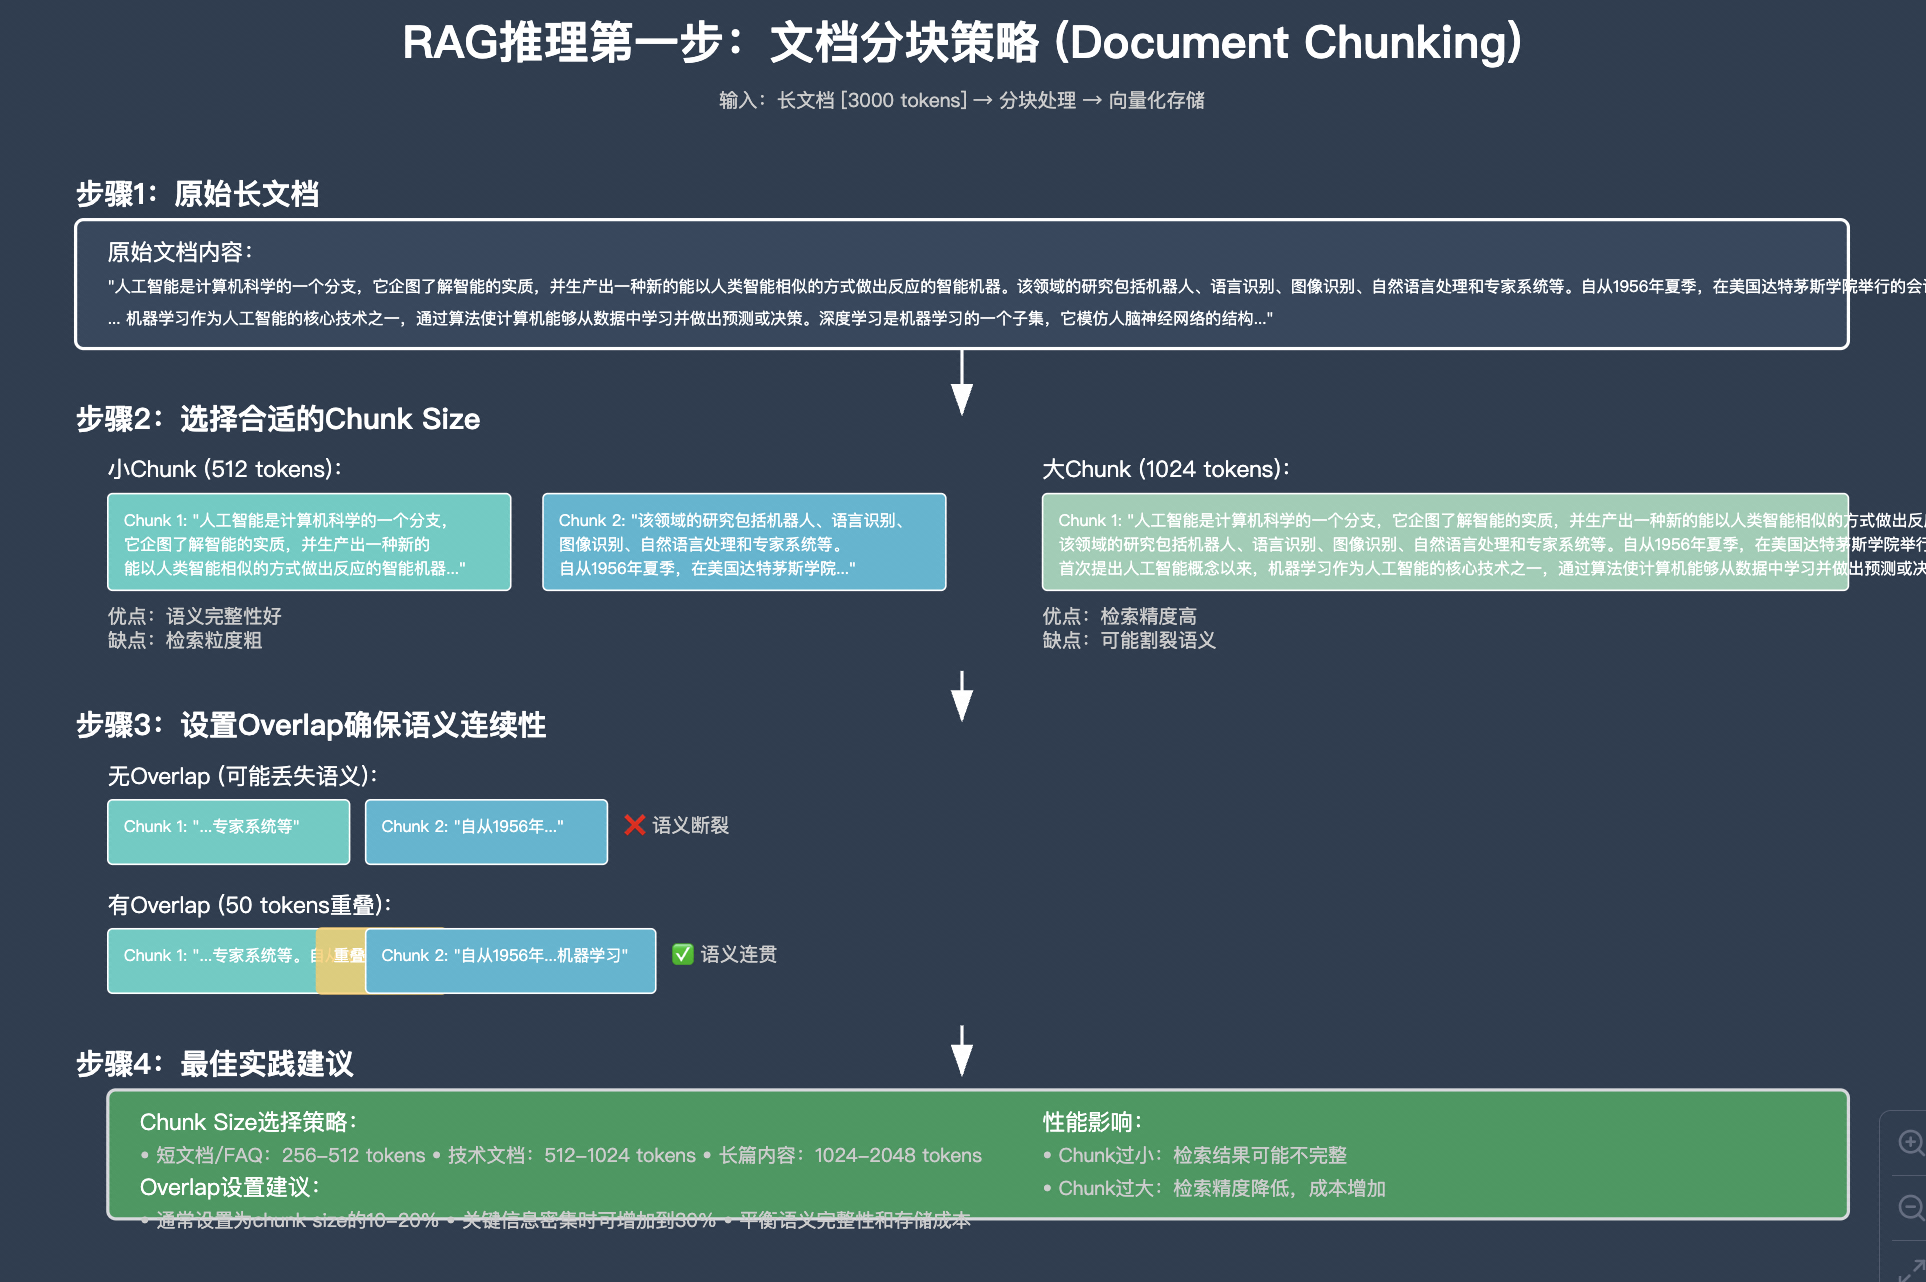

## 环境设置  
我们首先导入必要的库。

In [1]:
import fitz  # PyMuPDF，用于处理 PDF 文件
import os
import numpy as np
import json
from openai import OpenAI  # OpenAI API 客户端# cache: lpf2-00Wac lpf2-0eZ07


## 设置OpenAI API客户端
我们初始化OpenAI客户端以生成嵌入向量和回复。

In [2]:
from dotenv import load_dotenv
import os

# cache: lpf2-01Ub7 lpf2-0fCf0
load_dotenv()  # 加载.env文件（在 .env 里填写 DASHSCOPE_API_KEY）

# 模型调用改为阿里云百炼（OpenAI 兼容接口）：对话模型用 qwen-flash，向量模型用 text-embedding-v4
client = OpenAI(
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key=os.getenv("DASHSCOPE_API_KEY")  # 从环境变量中获取 API 密钥，不要写进代码或打印
)

# 百炼的 text-embedding-v4 单次最多 10 条文本：这里把 client.embeddings.create 包一层自动分批，
# 返回结构与 OpenAI 相同，后面的代码不用改
_embeddings_create = client.embeddings.create
def _batched_embeddings_create(model, input, **kwargs):
    if isinstance(input, str) or len(input) <= 10:
        return _embeddings_create(model=model, input=input, **kwargs)
    merged = None
    for i in range(0, len(input), 10):
        resp = _embeddings_create(model=model, input=input[i:i + 10], **kwargs)
        if merged is None:
            merged = resp
        else:
            merged.data.extend(resp.data)
    for idx, item in enumerate(merged.data):
        item.index = idx
    return merged
client.embeddings.create = _batched_embeddings_create


## 从PDF中提取文本  
首先，我们将从`AI_Information.pdf`文件中提取文本。

In [3]:
# checksum: lpf2-02Ga6 lpf2-1078c
def extract_text_from_pdf(pdf_path):
    """
    从PDF文件中提取文本。

    参数:
    pdf_path (str): PDF文件的路径。

    返回:
    str: 从PDF中提取的文本。
    """
    # 打开PDF文件
    mypdf = fitz.open(pdf_path)
    all_text = ""  # 初始化一个空字符串用于存储提取的文本
    
    # 遍历PDF中的每一页
    for page in mypdf:
        # 从当前页提取文本并添加间距
        all_text += page.get_text("text") + " "

    # 返回提取的文本，并去除首尾的空白字符
    return all_text.strip()

# 定义PDF文件的路径
pdf_path = "data/AI_Information.pdf"

# 从PDF文件中提取文本
extracted_text = extract_text_from_pdf(pdf_path)

# 打印提取文本的前500个字符
print(extracted_text[:500])

Understanding Artificial Intelligence 
Chapter 1: Introduction to Artificial Intelligence 
Artificial intelligence (AI) refers to the ability of a digital computer or computer-controlled robot 
to perform tasks commonly associated with intelligent beings. The term is frequently applied to 
the project of developing systems endowed with the intellectual processes characteristic of 
humans, such as the ability to reason, discover meaning, generalize, or learn from past 
experience. Over the past f


## 提取文本的分块
为了提高检索效率，我们将提取的文本分割为不同大小的重叠块。

In [4]:
# cache: lpf2-03Sec lpf2-11Sfa
def chunk_text(text, n, overlap):
    """
    将文本分割为重叠的块。

    参数:
    text (str): 需要分块的文本。
    n (int): 每个块的字符数。
    overlap (int): 块之间的重叠字符数。

    返回:
    List[str]: 一个包含文本块的列表。
    """
    chunks = []  # 初始化一个空列表来存储块
    for i in range(0, len(text), n - overlap):
        # 从当前索引到索引 + 块大小范围内追加一个块
        chunks.append(text[i:i + n])
    
    return chunks  # 返回文本块的列表

# 定义不同的块大小以进行评估
chunk_sizes = [128, 256, 512]

# 创建一个字典来存储每个块大小的文本块
text_chunks_dict = {size: chunk_text(extracted_text, size, size // 5) for size in chunk_sizes}

# 打印每个块大小创建的块的数量
for size, chunks in text_chunks_dict.items():
    print(f"Chunk Size: {size}, Number of Chunks: {len(chunks)}")

Chunk Size: 128, Number of Chunks: 326
Chunk Size: 256, Number of Chunks: 164
Chunk Size: 512, Number of Chunks: 82


## 创建文本块的嵌入
嵌入将文本转换为用于相似性搜索的数值表示。

In [5]:
from tqdm import tqdm

# generated: lpf2-04Q45 lpf2-12F2c
def create_embeddings(texts, model="text-embedding-v4"):
    """
    为一组文本生成嵌入向量。

    参数:
    texts (List[str]): 输入文本列表。
    model (str): 嵌入模型。

    返回:
    List[np.ndarray]: 数值化嵌入向量的列表。
    """
    # 使用指定模型创建嵌入向量
    response = client.embeddings.create(model=model, input=texts)
    # 将回复转换为 NumPy 数组的列表并返回
    return [np.array(embedding.embedding) for embedding in response.data]

# 为每个分块大小生成嵌入向量
# 遍历 text_chunks_dict 中每个分块大小及其对应的分块
chunk_embeddings_dict = {size: create_embeddings(chunks) for size, chunks in tqdm(text_chunks_dict.items(), desc="生成嵌入向量")}

生成嵌入向量:   0%|          | 0/3 [00:00<?, ?it/s]

生成嵌入向量:  33%|███▎      | 1/3 [00:10<00:20, 10.08s/it]

生成嵌入向量:  67%|██████▋   | 2/3 [00:15<00:07,  7.33s/it]

生成嵌入向量: 100%|██████████| 3/3 [00:18<00:00,  5.31s/it]

生成嵌入向量: 100%|██████████| 3/3 [00:18<00:00,  6.13s/it]

## 执行语义搜索  
我们使用余弦相似度来为用户查询找到最相关的文本片段。

In [6]:
# generated: lpf2-05G23 lpf2-13T53
def cosine_similarity(vec1, vec2):
    """
    计算两个向量之间的余弦相似度。

    参数:
    vec1 (np.ndarray): 第一个向量。
    vec2 (np.ndarray): 第二个向量。

    返回:
    float: 余弦相似度得分。
    """

    # 计算两个向量的点积
    return np.dot(vec1, vec2) / (np.linalg.norm(vec1) * np.linalg.norm(vec2))

In [7]:
# cache: lpf2-06Y19 lpf2-14Ad9
def retrieve_relevant_chunks(query, text_chunks, chunk_embeddings, k=5):
    """
    提取与查询最相关的文本块。

    参数:
    query (str): 用户查询。
    text_chunks (List[str]): 文本块列表。
    chunk_embeddings (List[np.ndarray]): 文本块的嵌入向量列表。
    k (int): 返回的最相关文本块数量。

    返回:
    List[str]: 最相关的文本块列表。
    """
    # 为查询生成嵌入向量 - 将查询作为列表传递并获取第一个元素
    query_embedding = create_embeddings([query])[0]
    
    # 计算查询嵌入与每个文本块嵌入之间的余弦相似度
    similarities = [cosine_similarity(query_embedding, emb) for emb in chunk_embeddings]
    
    # 获取最相似的k个文本块的索引
    top_indices = np.argsort(similarities)[-k:][::-1]
    
    # 返回最相关的k个文本块
    return [text_chunks[i] for i in top_indices]

In [8]:
# 从JSON文件中加载验证数据  
# revision: lpf2-07Ne9 lpf2-15H4a
with open('data/val.json') as f:  
    data = json.load(f)  

# 从验证数据中提取第一个查询  
query = data[3]['question']  

# 为每个chunk大小检索相关的片段  
retrieved_chunks_dict = {size: retrieve_relevant_chunks(query, text_chunks_dict[size], chunk_embeddings_dict[size]) for size in chunk_sizes}  

# 打印大小为256的检索到的片段  
print(retrieved_chunks_dict[256])

['y \nAI enhances public safety and security in smart cities by monitoring public spaces, detecting \nanomalies, and supporting emergency response. AI-powered systems improve crime prevention, \nenhance situational awareness, and support rapid response to incid', 'r Social Good \nAI is increasingly being used to address social and environmental challenges, such as climate \nchange, poverty, and healthcare disparities. AI for social good initiatives aim to leverage AI for \npositive impact. \nRegulation and Governance \nA', 't of self-driving cars, advanced medical \ndiagnostics, and sophisticated financial modeling tools demonstrates the broad and growing \napplications of AI. Concerns about ethical implications, bias, and job displacement are also \nincreasingly prominent. \nCha', 'mains. \nThese applications include: \nHealthcare \nAI is transforming healthcare through applications such as medical diagnosis, drug discovery, \npersonalized medicine, and robotic surgery. AI-powered too

## 基于检索块生成回复
让我们基于块大小为`256`的检索文本生成回复。

In [9]:
# 定义AI助手的系统提示
# checksum: lpf2-08Jcd lpf2-16Sff
system_prompt = "You are an AI assistant that strictly answers based on the given context. If the answer cannot be derived directly from the provided context, respond with: 'I do not have enough information to answer that.'"

def generate_response(query, system_prompt, retrieved_chunks, model="qwen-flash"):
    """
    基于检索到的片段生成AI回复。

    参数:
    query (str): 用户查询。
    retrieved_chunks (List[str]): 检索到的文本片段列表。
    model (str): AI模型。

    返回:
    str: AI生成的回复。
    """
    # 将检索到的片段组合成单一上下文字符串
    context = "\n".join([f"Context {i+1}:\n{chunk}" for i, chunk in enumerate(retrieved_chunks)])    
    # 通过结合上下文和查询创建用户提示
    user_prompt = f"{context}\n\nQuestion: {query}"

    # 使用指定模型生成AI回复
    response = client.chat.completions.create(
        model=model,
        temperature=0,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_prompt}
        ]
    )

    # 返回AI回复的内容
    return response.choices[0].message.content

# 为每个块大小生成AI回复
ai_responses_dict = {size: generate_response(query, system_prompt, retrieved_chunks_dict[size]) for size in chunk_sizes}

# 打印块大小为256的回复
print(ai_responses_dict[256])

I do not have enough information to answer that.


## 评估AI回复
我们使用强大的大型语言模型（LLM）根据忠实性和相关性对回复进行评分。

In [10]:
# 定义评估评分系统常量
# revision: lpf2-09A72 lpf2-1761f
SCORE_FULL = 1.0     # 完全匹配或完全令人满意
SCORE_PARTIAL = 0.5  # 部分匹配或部分令人满意
SCORE_NONE = 0.0     # 无匹配或不令人满意

In [11]:
# 定义严格的评估提示模板
# cache: lpf2-0aZdb lpf2-184b6
FAITHFULNESS_PROMPT_TEMPLATE = """
Evaluate the faithfulness of the AI response compared to the true answer.
User Query: {question}
AI Response: {response}
True Answer: {true_answer}

Faithfulness measures how well the AI response aligns with facts in the true answer, without hallucinations.

INSTRUCTIONS:
- Score STRICTLY using only these values:
    * {full} = Completely faithful, no contradictions with true answer
    * {partial} = Partially faithful, minor contradictions
    * {none} = Not faithful, major contradictions or hallucinations
- Return ONLY the numerical score ({full}, {partial}, or {none}) with no explanation or additional text.
"""

In [12]:
# cache: lpf2-0bI32 lpf2-19Y64
RELEVANCY_PROMPT_TEMPLATE = """
Evaluate the relevancy of the AI response to the user query.
User Query: {question}
AI Response: {response}

Relevancy measures how well the response addresses the user's question.

INSTRUCTIONS:
- Score STRICTLY using only these values:
    * {full} = Completely relevant, directly addresses the query
    * {partial} = Partially relevant, addresses some aspects
    * {none} = Not relevant, fails to address the query
- Return ONLY the numerical score ({full}, {partial}, or {none}) with no explanation or additional text.
"""

In [13]:
# cache: lpf2-0cW08
def evaluate_response(question, response, true_answer):
    """
    根据忠实性和相关性评估AI生成的回答质量。

    参数:
    question (str): 用户的原始问题。
    response (str): 正在评估的AI生成的回答。
    true_answer (str): 用作基准的真实答案。

    返回:
    Tuple[float, float]: 包含(faithfulness_score, relevancy_score)的元组。
                         每个分数为: 1.0 (完全)，0.5 (部分)，或 0.0 (无)。
    """
    # 格式化评估提示
    faithfulness_prompt = FAITHFULNESS_PROMPT_TEMPLATE.format(
            question=question, 
            response=response, 
            true_answer=true_answer,
            full=SCORE_FULL,
            partial=SCORE_PARTIAL,
            none=SCORE_NONE
    )
    
    relevancy_prompt = RELEVANCY_PROMPT_TEMPLATE.format(
            question=question, 
            response=response,
            full=SCORE_FULL,
            partial=SCORE_PARTIAL,
            none=SCORE_NONE
    )

    # 请求模型进行忠实性评估
    faithfulness_response = client.chat.completions.create(
           model="qwen-flash",
            temperature=0,
            messages=[
                    {"role": "system", "content": "You are an objective evaluator. Return ONLY the numerical score."},
                    {"role": "user", "content": faithfulness_prompt}
            ]
    )
    
    # 请求模型进行相关性评估
    relevancy_response = client.chat.completions.create(
            model="qwen-flash",
            temperature=0,
            messages=[
                    {"role": "system", "content": "You are an objective evaluator. Return ONLY the numerical score."},
                    {"role": "user", "content": relevancy_prompt}
            ]
    )
    
    # 提取分数并处理潜在的解析错误
    try:
            faithfulness_score = float(faithfulness_response.choices[0].message.content.strip())
    except ValueError:
            print("Warning: Could not parse faithfulness score, defaulting to 0")
            faithfulness_score = 0.0
            
    try:
            relevancy_score = float(relevancy_response.choices[0].message.content.strip())
    except ValueError:
            print("Warning: Could not parse relevancy score, defaulting to 0")
            relevancy_score = 0.0

    return faithfulness_score, relevancy_score

# 第一个验证数据的真实答案
true_answer = data[3]['ideal_answer']

# 对于块大小 256 和 128 评估回复
faithfulness, relevancy = evaluate_response(query, ai_responses_dict[256], true_answer)
faithfulness2, relevancy2 = evaluate_response(query, ai_responses_dict[128], true_answer)

# 打印评估分数
print(f"Faithfulness Score (Chunk Size 256): {faithfulness}")
print(f"Relevancy Score (Chunk Size 256): {relevancy}")

print(f"\n")

print(f"Faithfulness Score (Chunk Size 128): {faithfulness2}")
print(f"Relevancy Score (Chunk Size 128): {relevancy2}")

Faithfulness Score (Chunk Size 256): 0.0
Relevancy Score (Chunk Size 256): 0.0


Faithfulness Score (Chunk Size 128): 0.5
Relevancy Score (Chunk Size 128): 0.0


In [ ]:
# checksum: lpf2-0dZ82
